# Les nombres premiers « connaissent » les zéros de ζ
### La positivité de Weil, en haute précision

Ce carnet accompagne le dossier `exploration/` du dépôt *Musique-Des-Premiers*. Il refait, en petit, une expérience d'Alain Connes et Caterina Consani (2021).

**L'idée.** On prend une onde paire φ qui ne vit qu'entre 1/√x et √x (en échelle logarithmique). Son *énergie de Weil* W(φ) se calcule de deux façons, qui donnent le même nombre :
- avec les seuls nombres premiers (et leurs puissances) inférieurs à x, plus quelques constantes comme π ;
- ou comme la somme, sur tous les zéros ½ + iγ de ζ, des carrés φ̂(γ)².

Si l'hypothèse de Riemann est vraie, c'est une somme de carrés, donc W(φ) ≥ 0. Weil a montré la réciproque : si W(φ) ≥ 0 pour toutes les ondes, avec x aussi grand qu'on veut, l'hypothèse est vraie.

**Ce que fait le carnet.** Pour chaque x, il construit la matrice de cette énergie sur N ondes de base, **sans utiliser aucun zéro**, puis :
1. il vérifie qu'elle est définie positive ;
2. il cherche l'onde d'énergie minimale ;
3. il regarde où le « son » φ̂ de cette onde s'annule, et compare avec les vrais zéros de ζ, recalculés à part.

**À lire d'abord.** Rien ici ne démontre l'hypothèse : on ne teste que des ondes de taille finie.

**Pour l'utiliser.** Menu *Exécution → Tout exécuter*. Avec les réglages de départ, tout tourne en moins d'une minute.

## 1. Outils en haute précision

π (formule de Machin), sinus et cosinus, constante d'Euler γ (algorithme de Brent–McMillan), nœuds de Gauss–Legendre, liste des puissances de premiers. Tout repose sur le module standard `decimal` : rien à installer.

In [1]:
from decimal import Decimal as D, getcontext, localcontext
import math

_cache = {}

def set_precision(digits):
    getcontext().prec = int(digits)

def _prec():
    return getcontext().prec

def pi():
    p = _prec(); key = ("pi", p)
    if key not in _cache:
        with localcontext() as ctx:
            ctx.prec = p + 10
            eps = D(10) ** (-(p + 8))
            def arctan_inv(x):                      # arctan(1/x) pour x entier ≥ 2
                x = D(x); x2 = x * x; term = 1 / x; s = term; k = 1; sign = -1
                while True:
                    term = term / x2
                    t = term / (2 * k + 1)
                    if t < eps: break
                    s += sign * t; sign = -sign; k += 1
                return s
            val = 4 * (4 * arctan_inv(5) - arctan_inv(239))        # formule de Machin
        _cache[key] = +val
    return _cache[key]

def sincos(x):
    """(sin x, cos x) en précision courante."""
    p = _prec()
    with localcontext() as ctx:
        ctx.prec = p + 12
        P = pi(); twopi = 2 * P
        x = D(x)
        x = x - twopi * (x / twopi).to_integral_value()           # ramené dans [−π, π]
        x2 = x * x; eps = D(10) ** (-(p + 10))
        c = D(1); term = D(1); k = 0
        while True:
            k += 2; term = -term * x2 / (k * (k - 1)); c += term
            if abs(term) < eps: break
        s = x; term = x; k = 1
        while True:
            k += 2; term = -term * x2 / (k * (k - 1)); s += term
            if abs(term) < eps: break
    return +s, +c

def euler_gamma():
    """Constante d'Euler γ_E par l'algorithme de Brent–McMillan (erreur ~ e^{−4n})."""
    p = _prec(); key = ("gamma", p)
    if key not in _cache:
        with localcontext() as ctx:
            ctx.prec = p + 15
            n = int(p * math.log(10) / 4) + 6
            term = D(1); H = D(0); A = D(0); B = D(0); k = 0
            eps = D(10) ** (-(p + 12))
            while True:
                if k > 0:
                    term = term * n * n / (k * k); H += D(1) / k
                A += term * H; B += term; k += 1
                if k > 3 * n and term < eps * B: break
            val = A / B - D(n).ln()
        _cache[key] = +val
    return _cache[key]

def gauss_legendre(n):
    """Nœuds et poids de Gauss–Legendre sur [−1, 1] (Newton sur P_n, en précision courante)."""
    p = _prec(); key = ("gl", n, p)
    if key in _cache: return _cache[key]
    out = []
    with localcontext() as ctx:
        ctx.prec = p + 10
        eps = D(10) ** (-(p + 6))
        def legendre(x):
            p0, p1 = D(1), x
            for k in range(2, n + 1):
                p0, p1 = p1, ((2 * k - 1) * x * p1 - (k - 1) * p0) / k
            return p1, n * (x * p1 - p0) / (x * x - 1)
        for i in range(1, n // 2 + 1):
            x = D(repr(math.cos(math.pi * (i - 0.25) / (n + 0.5))))
            for _ in range(200):
                pn, dpn = legendre(x); dx = pn / dpn; x -= dx
                if abs(dx) < eps: break
            pn, dpn = legendre(x)
            w = 2 / ((1 - x * x) * dpn * dpn)
            out += [(x, w), (-x, w)]
        if n % 2 == 1:
            pn, dpn = legendre(D(0)); out.append((D(0), 2 / (dpn * dpn)))
    out = [(+x, +w) for x, w in out]
    _cache[key] = out
    return out

def prime_powers_below(X):
    """[(n, p)] pour les puissances de premiers n = p^k avec 2 ≤ n < X."""
    out = []
    for n in range(2, int(math.ceil(X))):
        m = n; p = 2
        while m % p: p += 1
        while m % p == 0: m //= p
        if m == 1: out.append((n, p))
    return out

## 2. La matrice de l'énergie de Weil, sans aucun zéro

Les ondes sont φ(t) = Σ c<sub>m</sub> cos(K<sub>m</sub> t) sur [−a, a], avec K<sub>m</sub> = (m − ½)π/a et a = ½ ln x. Avec g(u) = ∫ φ(t) φ(t + u) dt, la formule explicite de Guinand–Weil donne :

W(φ) = 2 φ̂(i/2)² − g(0) [ln π + γ + ln(1 − e<sup>−4a</sup>)] + 2 ∫<sub>0</sub><sup>2a</sup> [g(0) e<sup>−2u</sup> − e<sup>−u/2</sup> g(u)] / (1 − e<sup>−2u</sup>) du − 2 Σ<sub>n<x</sub> Λ(n) n<sup>−1/2</sup> g(ln n)

Le premier terme vient des pôles de ζ, les deux suivants de la « place archimédienne » (la fonction Γ), le dernier des nombres premiers. Tout est en formules fermées, sauf deux familles d'intégrales sur [0, 2a], calculées par Gauss–Legendre composite.

In [2]:
def basis(X, N):
    a = D(X).ln() / 2
    P = pi()
    K = [(D(m) - D("0.5")) * P / a for m in range(1, N + 1)]
    return a, K

def G_matrix(u, a, K):
    """G_jk(u) = ∫ e_j(t) e_k(t+u) dt en formule fermée (matrice symétrique)."""
    N = len(K); s = []; c = []
    for k in K:
        sk, ck = sincos(k * u); s.append(sk); c.append(ck)
    G = [[D(0)] * N for _ in range(N)]
    for i in range(N):
        G[i][i] = ((2 * a - u) * c[i] + s[i] / K[i]) / 2
        for j in range(i + 1, N):
            v = ((s[j] - s[i]) / (K[i] - K[j]) + (s[i] + s[j]) / (K[i] + K[j])) / 2
            if (i + j) % 2: v = -v
            G[i][j] = v; G[j][i] = v
    return G

def weil_matrix(X, N, panels=None, nodes_per_panel=40, parts=False):
    """Matrice M de la forme de Weil sur la base {cos(K_m t)}, m = 1..N, pour des ondes vivant entre 1/√X et √X."""
    a, K = basis(X, N)
    P = pi()
    sgn = [1 if m % 2 else -1 for m in range(1, N + 1)]
    e = (a / 2).exp(); cosh_half = (e + 1 / e) / 2
    A = [sgn[i] * 2 * K[i] * cosh_half / (K[i] * K[i] + D("0.25")) for i in range(N)]
    M_pole = [[2 * A[i] * A[j] for j in range(N)] for i in range(N)]
    const = a * (P.ln() + euler_gamma() + (1 - (-4 * a).exp()).ln())
    # intégrales archimédiennes : S_m = ∫ e^{−u/2} sin(K_m u)/(1 − e^{−2u}) du ; Dg_m = ∫ [a e^{−2u} − e^{−u/2} G_mm(u)]/(1 − e^{−2u}) du
    L = 2 * a
    if panels is None:
        panels = max(8, int(float(K[-1]) * float(L) / 5) + 1)        # ~5 radians d'oscillation par panneau au plus
    base = gauss_legendre(nodes_per_panel)
    h = L / panels
    S = [D(0)] * N; Dg = [D(0)] * N
    for ip in range(panels):
        mid = h * ip + h / 2
        for xg, wg in base:
            u = mid + h / 2 * xg; w = h / 2 * wg
            e2 = (-2 * u).exp(); eh = (-u / 2).exp(); den = 1 - e2
            s1, c1 = sincos(K[0] * u)
            s2 = 2 * s1 * c1; c2 = 1 - 2 * s1 * s1                # angle 2θ, avec K_m u = (2m − 1)θ
            sm, cm = s1, c1
            f1 = w * eh / den; f2 = w / den
            for m in range(N):
                S[m] += f1 * sm
                Dg[m] += f2 * (a * e2 - eh * ((2 * a - u) * cm + sm / K[m]) / 2)
                sm, cm = sm * c2 + cm * s2, cm * c2 - sm * s2
    M_arch = [[D(0)] * N for _ in range(N)]
    for i in range(N):
        M_arch[i][i] = 2 * Dg[i]
        for j in range(i + 1, N):
            v = -((S[j] - S[i]) / (K[i] - K[j]) + (S[i] + S[j]) / (K[i] + K[j])) / 2
            if (i + j) % 2: v = -v
            M_arch[i][j] = M_arch[j][i] = 2 * v
    M_prime = [[D(0)] * N for _ in range(N)]
    for n, p in prime_powers_below(X):
        u = D(n).ln()
        if u >= 2 * a: continue
        G = G_matrix(u, a, K); coef = 2 * D(p).ln() / D(n).sqrt()
        for i in range(N):
            for j in range(N):
                M_prime[i][j] -= coef * G[i][j]
    M = [[M_pole[i][j] + M_arch[i][j] + M_prime[i][j] for j in range(N)] for i in range(N)]
    for i in range(N): M[i][i] -= const
    if parts:
        return M, dict(pole=M_pole, arch=M_arch, prime=M_prime, const=const, a=a, K=K)
    return M

## 3. Algèbre linéaire en haute précision

Factorisation de Cholesky (tous les pivots > 0 ⇔ la matrice est définie positive) et itération inverse pour la plus petite valeur propre.

In [3]:
def cholesky_pivots(M):
    """Pivots de la factorisation LDLᵀ ; tous > 0  ⇔  M définie positive (à la précision du calcul)."""
    N = len(M); A = [row[:] for row in M]; piv = []
    for k in range(N):
        d = A[k][k]; piv.append(d)
        if d <= 0: return piv
        for i in range(k + 1, N):
            l = A[i][k] / d
            if l != 0:
                Ai = A[i]; Ak = A[k]
                for j in range(k + 1, N): Ai[j] -= l * Ak[j]
    return piv

def solve(M, b):
    N = len(M); A = [M[i][:] + [b[i]] for i in range(N)]
    for k in range(N):
        p = max(range(k, N), key=lambda i: abs(A[i][k]))
        A[k], A[p] = A[p], A[k]
        for i in range(k + 1, N):
            l = A[i][k] / A[k][k]
            if l != 0:
                Ai = A[i]; Ak = A[k]
                for j in range(k, N + 1): Ai[j] -= l * Ak[j]
    x = [D(0)] * N
    for i in range(N - 1, -1, -1):
        x[i] = (A[i][N] - sum(A[i][j] * x[j] for j in range(i + 1, N))) / A[i][i]
    return x

def _normalize(v):
    n = sum(x * x for x in v).sqrt(); return [x / n for x in v]

def rayleigh(M, v):
    return sum(v[i] * sum(M[i][j] * v[j] for j in range(len(v))) for i in range(len(v)))

def smallest_eigenpair(M, v0, iterations=8):
    """Itération inverse : converge vers la plus petite valeur propre et son vecteur."""
    v = _normalize([D(repr(float(x))) for x in v0])
    for _ in range(iterations):
        v = _normalize(solve(M, v))
    lam = rayleigh(M, v)
    r = [sum(M[i][j] * v[j] for j in range(len(v))) - lam * v[i] for i in range(len(v))]
    res = sum(x * x for x in r).sqrt()
    return lam, v, res

## 4. Le « son » de la meilleure onde

φ̂(r) = cos(ra) Σ v<sub>m</sub> (−1)<sup>m+1</sup> 2K<sub>m</sub>/(K<sub>m</sub>² − r²), et une méthode de la sécante pour localiser ses zéros.

In [4]:
def phi_hat(v, a, K, r):
    """φ̂(r) = cos(ra) Σ v_m (−1)^{m+1} 2 K_m / (K_m² − r²)."""
    r = D(r); s = D(0)
    for m, (vm, km) in enumerate(zip(v, K)):
        t = 2 * km * vm / (km * km - r * r)
        s += t if m % 2 == 0 else -t
    return sincos(r * a)[1] * s

def refine_zero(f, r0, tol_digits=None):
    """Sécante à partir d'une estimation r0 (float)."""
    p = _prec(); tol = D(10) ** (-(tol_digits or p - 8))
    x0 = D(repr(r0)); x1 = x0 + D("1e-7")
    f0, f1 = f(x0), f(x1)
    for _ in range(200):
        if f1 == f0: break
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        x0, f0, x1 = x1, f1, x2; f1 = f(x1)
        if abs(x1 - x0) < tol: break
    return x1

## 5. Zéros de référence

Pour comparer, on recalcule les vrais zéros de ζ indépendamment (formule d'Euler–Maclaurin, sécante complexe : on ne suppose même pas qu'ils sont sur la droite).

In [5]:
def _bernoulli_even(M):
    from fractions import Fraction
    B = [Fraction(1)]
    for m in range(1, 2 * M + 1):
        B.append(-sum(math.comb(m + 1, j) * B[j] for j in range(m)) / (m + 1))
    return [B[2 * k] for k in range(1, M + 1)]

def zeta(s_re, s_im, terms=150, M=40):
    """ζ(s) pour s = s_re + i s_im (Decimal), par Euler–Maclaurin. Renvoie (Re, Im)."""
    key = ("bern", M)
    if key not in _cache: _cache[key] = _bernoulli_even(M)
    Bs = _cache[key]
    sr, si = D(s_re), D(s_im)
    tot_r = D(0); tot_i = D(0)
    for n in range(1, terms):
        ln = D(n).ln(); mag = (-sr * ln).exp(); sn, cn = sincos(si * ln)
        tot_r += mag * cn; tot_i -= mag * sn                       # n^{−s} = n^{−σ} (cos(t ln n) − i sin(t ln n))
    Nn = D(terms); lnN = Nn.ln(); mag = (-sr * lnN).exp(); sN, cN = sincos(si * lnN)
    Ns_r, Ns_i = mag * cN, -mag * sN                               # N^{−s}
    # N^{1−s}/(s − 1)
    num_r, num_i = Nn * Ns_r, Nn * Ns_i; dr, di = sr - 1, si; den = dr * dr + di * di
    tot_r += (num_r * dr + num_i * di) / den; tot_i += (num_i * dr - num_r * di) / den
    tot_r += Ns_r / 2; tot_i += Ns_i / 2
    # Σ B_{2k}/(2k)! s(s+1)…(s+2k−2) N^{−s−2k+1}
    pr, pi_ = sr, si                      # produit s(s+1)…(s+2k−2), commence à s
    powr, powi = Ns_r / Nn, Ns_i / Nn     # N^{−s−1}
    fact = D(1)
    for k in range(1, M + 1):
        fact = fact * (2 * k) * (2 * k - 1) if k > 1 else D(2)
        b = D(Bs[k - 1].numerator) / D(Bs[k - 1].denominator)
        cr, ci = b / fact * (pr * powr - pi_ * powi), b / fact * (pr * powi + pi_ * powr)
        tot_r += cr; tot_i += ci
        # prochain : produit × (s + 2k − 1)(s + 2k), puissance × N^{−2}
        for add in (2 * k - 1, 2 * k):
            ar, ai = sr + add, si
            pr, pi_ = pr * ar - pi_ * ai, pr * ai + pi_ * ar
        powr, powi = powr / (Nn * Nn), powi / (Nn * Nn)
    return tot_r, tot_i

def zeta_zero(gamma_estimate, terms=150, M=40):
    """Zéro de ζ près de ½ + i·γ (sécante complexe en 2D, sans supposer qu'il est sur la droite)."""
    p = _prec(); tol = D(10) ** (-(p - 10))
    s0 = (D("0.5"), D(repr(gamma_estimate))); s1 = (D("0.5"), s0[1] + D("1e-6"))
    f0 = zeta(*s0, terms=terms, M=M); f1 = zeta(*s1, terms=terms, M=M)
    for _ in range(100):
        # s2 = s1 − f1 (s1 − s0)/(f1 − f0)   (complexes)
        dr, di = s1[0] - s0[0], s1[1] - s0[1]; gr, gi = f1[0] - f0[0], f1[1] - f0[1]
        den = gr * gr + gi * gi
        if den == 0: break
        qr, qi = (dr * gr + di * gi) / den, (di * gr - dr * gi) / den   # (s1 − s0)/(f1 − f0)
        stepr, stepi = f1[0] * qr - f1[1] * qi, f1[0] * qi + f1[1] * qr
        s2 = (s1[0] - stepr, s1[1] - stepi)
        s0, f0, s1 = s1, f1, s2; f1 = zeta(*s1, terms=terms, M=M)
        if abs(stepr) + abs(stepi) < tol: break
    return s1                                                       # (partie réelle, γ)

## 6. Réglages

Pour aller plus loin, essaie par exemple `PREC = 150`, `N = 60` et `XS = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31]` (quelques minutes au plus).

In [6]:
PREC = 90                      # chiffres significatifs utilisés dans tous les calculs
N = 40                         # nombre d'ondes de base
XS = [2, 3, 5, 7, 11, 13]      # pour chaque x : nombres premiers et puissances de premiers < x
set_precision(PREC)

In [7]:
import time
ESTIMATIONS = [14.134725141734693, 21.022039638771555, 25.010857580145688, 30.424876125859513, 32.935061587739189,
               37.586178158825671, 40.918719012147495, 43.327073280915000, 48.005150881167160, 49.773832477672302]
t0 = time.time()
REF = [zeta_zero(g, terms=250, M=50)[1] for g in ESTIMATIONS]
print("10 zéros de référence recalculés à %d chiffres en %.0f s" % (PREC, time.time() - t0))
print("γ1 =", str(REF[0])[:60], "…")
# Contrôle indépendant avec mpmath, s'il est disponible (c'est le cas sur Colab)
try:
    import mpmath
    mpmath.mp.dps = PREC
    g1 = D(mpmath.nstr(mpmath.zetazero(1).imag, PREC))
    print("Écart avec mpmath.zetazero(1) : %.0e" % float(abs(g1 - REF[0])))
except Exception as e:
    print("(Contrôle mpmath non disponible ici :", type(e).__name__ + ")")

10 zéros de référence recalculés à 90 chiffres en 3 s
γ1 = 14.134725141734693790457251983562470270784257115699243175685 …
(Contrôle mpmath non disponible ici : ModuleNotFoundError)


## 7. L'expérience

Pour chaque x : matrice de Weil, test de positivité, onde d'énergie minimale, puis nombre de décimales justes de ses zéros comparés aux 10 premiers zéros de ζ.

In [8]:
import numpy as np
results = {}
print(" x  | définie positive | plus petite énergie | décimales justes de γ1 … γ10")
for X in XS:
    t0 = time.time()
    M = weil_matrix(X, N)
    piv = cholesky_pivots(M)
    positive = len(piv) == N and all(p > 0 for p in piv)
    w, V = np.linalg.eigh(np.array([[float(v) for v in row] for row in M]))   # point de départ approché
    lam, v, res = smallest_eigenpair(M, V[:, 0], iterations=10)              # puis affinage en haute précision
    a, K = basis(X, N)
    digits = []
    for g in REF:
        z = refine_zero(lambda r: phi_hat(v, a, K, r), float(g))
        err = abs(z - g)
        digits.append(max(0, int(-err.log10())) if err > 0 else PREC)
    results[X] = dict(energy=lam, digits=digits, positive=positive)
    print("%3d | %-16s | %19.3e | %s   (%.0f s)" % (X, "oui" if positive else "NON", float(lam),
                                                     " ".join("%2d" % d for d in digits), time.time() - t0))

 x  | définie positive | plus petite énergie | décimales justes de γ1 … γ10
  2 | oui              |           4.770e-04 |  0  0  0  0  0  0  0  0  0  0   (1 s)
  3 | oui              |           3.300e-08 |  4  2  1  0  0  0  0  0  0  0   (1 s)
  5 | oui              |           8.301e-18 | 13 10  9  7  6  4  3  3  1  1   (1 s)
  7 | oui              |           8.489e-28 | 23 20 18 16 15 13 11 10  8  8   (1 s)
 11 | oui              |           4.300e-47 | 42 39 37 34 33 31 29 28 25 24   (1 s)
 13 | oui              |           1.073e-53 | 49 45 43 40 39 37 35 34 31 30   (1 s)


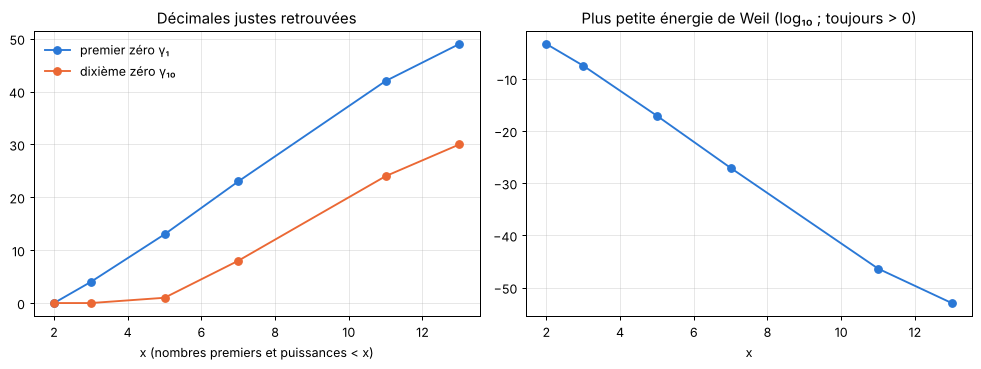

In [9]:
import matplotlib.pyplot as plt
xs = list(results)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(xs, [results[x]["digits"][0] for x in xs], "o-", color="#2a78d6", label="premier zéro γ₁")
ax1.plot(xs, [results[x]["digits"][9] for x in xs], "o-", color="#eb6834", label="dixième zéro γ₁₀")
ax1.set_title("Décimales justes retrouvées"); ax1.set_xlabel("x (nombres premiers et puissances < x)")
ax1.legend(frameon=False); ax1.grid(alpha=0.3)
ax2.plot(xs, [float(results[x]["energy"].log10()) for x in xs], "o-", color="#2a78d6")
ax2.set_title("Plus petite énergie de Weil (log₁₀ ; toujours > 0)"); ax2.set_xlabel("x"); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Ce que ça montre, et ce que ça ne montre pas

**Ce que ça montre.**
- Pour chaque x testé, la matrice est définie positive : la positivité de Weil tient pour ces ondes.
- L'onde la plus discrète se tait pile sur les zéros de ζ. Pour avoir le moins d'énergie possible, elle doit être muette à chaque γ. Les zéros sortent donc des nombres premiers seuls, avec de plus en plus de décimales quand x grandit.

**Ce que ça ne montre pas.**
- L'hypothèse de Riemann demande la positivité pour **toutes** les ondes, avec x aussi grand qu'on veut. Ici x reste fini.
- L'énergie minimale fond à toute vitesse : environ 10⁻⁴⁸ dès x = 11, 10⁻⁹⁹ vers x = 31. Aucun calcul fini ne peut aller jusqu'à l'infini ; il faut une *raison* pour laquelle elle reste positive.
- C'est la stratégie de Connes, Consani et Moscovici (2025) : construire, à partir des nombres premiers ≤ x, des opérateurs dont les « notes » sont forcément sur la droite, puis démontrer qu'ils convergent vers les vrais zéros. Cette convergence n'est pas démontrée.

**Pour aller plus loin.** Augmente `PREC`, `N` et `XS` dans les réglages. Essaie aussi une base de taille différente, ou d'autres familles d'ondes.

## Bonus : le monde où l'hypothèse est démontrée

Pour la courbe y² = x³ + x + 1, on compte ses points modulo chaque nombre premier p, ce qui donne a<sub>p</sub> = p + 1 − (nombre de points). Dans ce monde, l'hypothèse de Riemann dit |a<sub>p</sub>| ≤ 2√p : les deux zéros de la fonction zêta de la courbe sont exactement sur la droite Re s = ½. C'est un théorème : Hasse (années 1930) pour ces courbes, Weil (1948) pour toutes les courbes, Deligne (1974) en général.

1958 nombres premiers ; plus grande valeur de |a_p|/(2√p) : 0.9997 (jamais au-delà de 1)


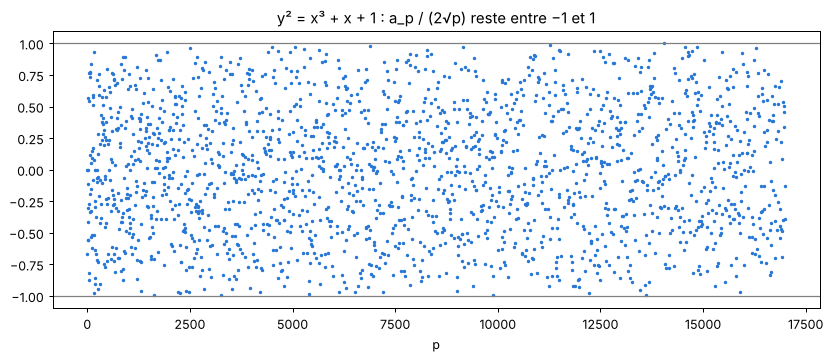

In [10]:
import math
PMAX = 17000
crible = np.ones(PMAX + 1, bool); crible[:2] = False
for i in range(2, int(PMAX ** 0.5) + 1):
    if crible[i]: crible[i * i::i] = False
ps, ys = [], []
for p in np.nonzero(crible)[0]:
    p = int(p)
    if p in (2, 31): continue                       # mauvaise réduction (discriminant −16·31)
    xv = np.arange(p, dtype=np.int64)
    carre = np.zeros(p, bool); carre[(xv * xv) % p] = True
    val = ((xv * xv % p) * xv + xv + 1) % p
    legendre = np.where(val == 0, 0, np.where(carre[val], 1, -1))
    ps.append(p); ys.append(-int(legendre.sum()) / (2 * math.sqrt(p)))   # a_p = −Σ (symbole de Legendre)
print(len(ps), "nombres premiers ; plus grande valeur de |a_p|/(2√p) :", round(max(abs(y) for y in ys), 4), "(jamais au-delà de 1)")
plt.figure(figsize=(11, 4))
plt.scatter(ps, ys, s=3, color="#2a78d6")
plt.axhline(1, color="gray", lw=1); plt.axhline(-1, color="gray", lw=1)
plt.title("y² = x³ + x + 1 : a_p / (2√p) reste entre −1 et 1"); plt.xlabel("p"); plt.show()

## Sources
- A. Connes, C. Consani, *Spectral triples and ζ-cycles* (2021) — [arXiv:2106.01715](https://arxiv.org/abs/2106.01715)
- A. Connes, C. Consani, H. Moscovici, *Zeta Spectral Triples* (2025) — [arXiv:2511.22755](https://arxiv.org/abs/2511.22755)
- A. Groskin, *High-Precision Approximation of Riemann Zeros via the Truncated Weil Form* (2026) — [arXiv:2605.20224](https://arxiv.org/abs/2605.20224)

Carnet réalisé avec l'aide de Claude (Anthropic).